In [2]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("loan_approval_dataset.csv")
df.head()
#df[""].value_count()


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [3]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [4]:
print(type(df))
print(df.columns.tolist())
df.columns = df.columns.str.strip()

<class 'pandas.DataFrame'>
['loan_id', ' no_of_dependents', ' education', ' self_employed', ' income_annum', ' loan_amount', ' loan_term', ' cibil_score', ' residential_assets_value', ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value', ' loan_status']


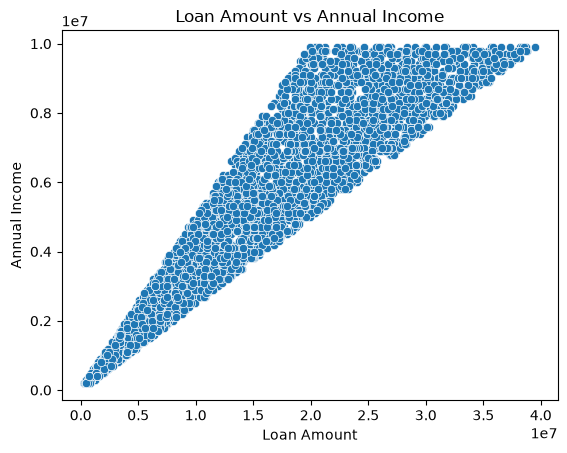

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=df, x="loan_amount", y="income_annum")

plt.xlabel("Loan Amount")
plt.ylabel("Annual Income")
plt.title("Loan Amount vs Annual Income")

plt.show()

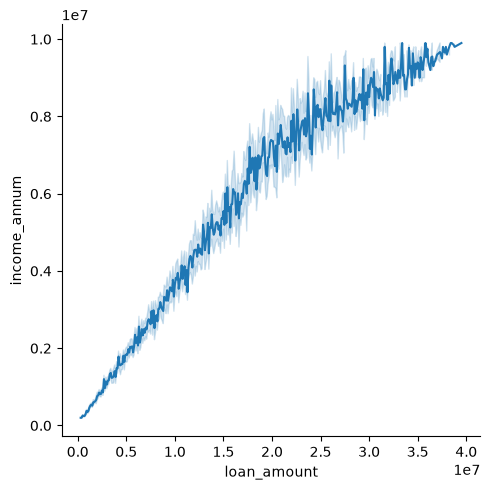

In [6]:
#dowjones = sns.load_dataset("dowjones")
sns.relplot(data=df, x="loan_amount", y="income_annum", kind="line")


<Axes: xlabel='loan_amount', ylabel='Density'>

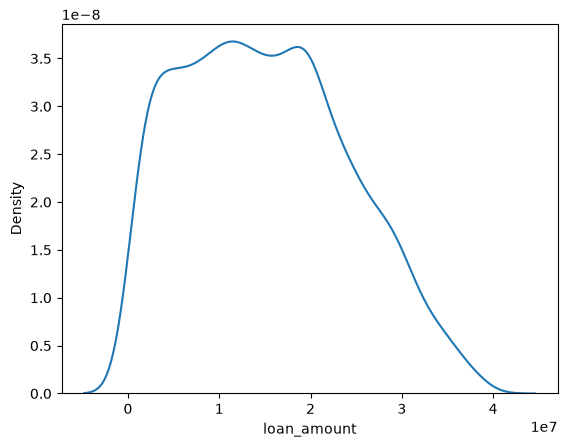

In [7]:
sns.kdeplot(data=df,x="loan_amount")

<Axes: xlabel='income_annum', ylabel='Density'>

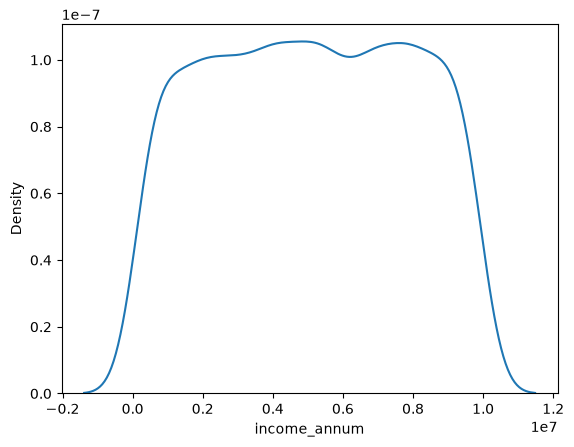

In [8]:
sns.kdeplot(data=df,x="income_annum")

In [9]:
import numpy as np
from scipy.stats import boxcox

df["loan_amount_boxcox"], lam = boxcox(df["loan_amount"])

print("Optimal Lambda:", lam)

Optimal Lambda: 0.6116259726139778


<Axes: xlabel='loan_amount_boxcox', ylabel='Density'>

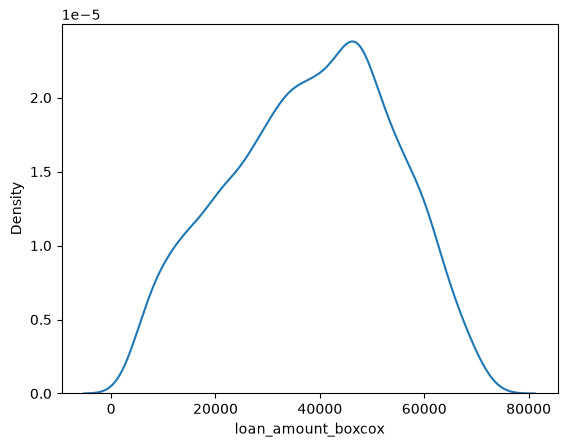

In [10]:
sns.kdeplot(data=df,x=df["loan_amount_boxcox"])

<Axes: xlabel='loan_amount_boxcox'>

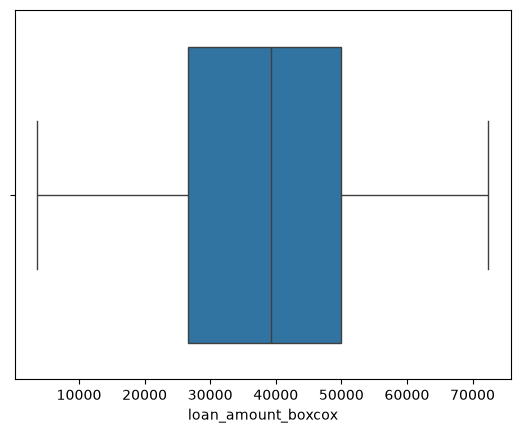

In [11]:
sns.boxplot(data=df,x="loan_amount_boxcox")

In [12]:
from sklearn.preprocessing import QuantileTransformer

qt = QuantileTransformer(
    n_quantiles=1000,
    output_distribution="normal",
    random_state=42
)

df["loan_amount_quantile"] = qt.fit_transform(
    df[["loan_amount"]]
).ravel()

In [13]:
import numpy as np
from scipy.stats import boxcox
df["income_annum_boxcox"], lam = boxcox(df["income_annum"])
print("Optimal Lambda:", lam)

Optimal Lambda: 0.7382518008226543


<Axes: xlabel='income_annum_boxcox', ylabel='Density'>

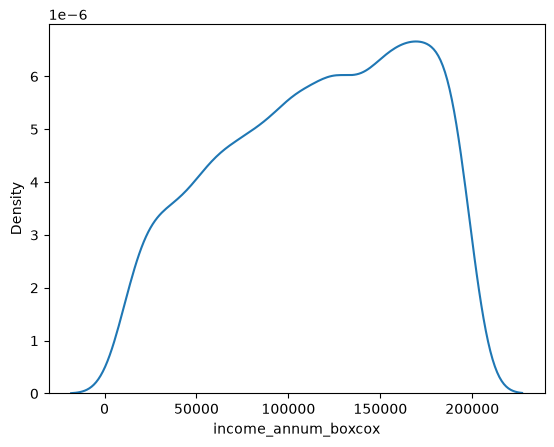

In [14]:
sns.kdeplot(data=df,x="income_annum_boxcox")

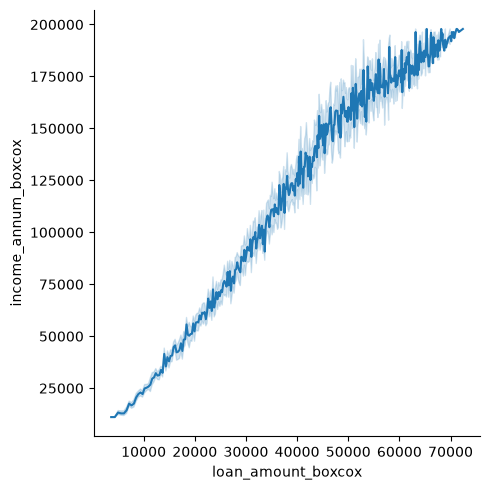

In [15]:
#dowjones = sns.load_dataset("dowjones")
sns.relplot(data=df, x="loan_amount_boxcox", y="income_annum_boxcox", kind="line")


In [16]:

data=df
corr = data['loan_amount_boxcox'].corr(data['income_annum_boxcox'])
print(corr)

0.9471068988751771


In [17]:
data=df
corr = data['loan_amount'].corr(data['income_annum'])
print (corr)

0.9274699109871488


In [18]:
df.isnull().sum()

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
loan_amount_boxcox          0
loan_amount_quantile        0
income_annum_boxcox         0
dtype: int64

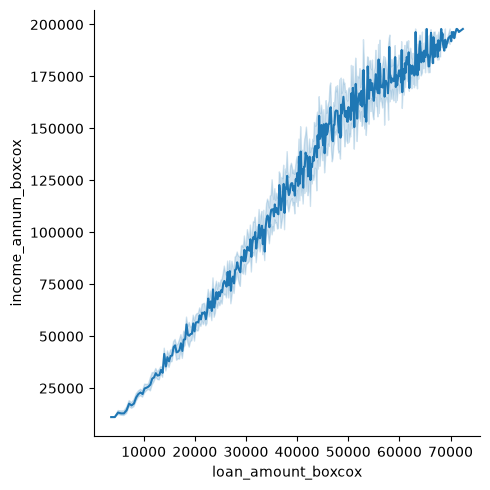

In [19]:

#dowjones = sns.load_dataset("dowjones")
sns.relplot(data=df, x="loan_amount_boxcox", y="income_annum_boxcox", kind="line")


In [20]:
import pandas as pd
from scipy.stats import skew, kurtosis

columns = [
    'income_annum',   
]

for col in columns:
    print(f"\n{col}")
    print("Skewness:", skew(df[col].dropna()))
    print("Kurtosis:", kurtosis(df[col].dropna()))


income_annum
Skewness: -0.012809922048151696
Kurtosis: -1.1827493293521922


we finaly concat loan_amount_boxcox and income_anume_boxcox this two columns

In [21]:
from scipy.stats import boxcox
df.columns = df.columns.str.strip()
df["loan_amount"] = boxcox(df["loan_amount"])[0]
df["income_annum"] = boxcox(df["income_annum"])[0]
df.drop(df.columns[-3:], axis=1, inplace=True)

df.head()


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,193404.580257,61068.480619,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,103202.299825,35293.577788,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,185916.168564,60818.308468,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,172158.153133,62062.737911,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,196371.170861,53657.953213,20,382,12400000,8200000,29400000,5000000,Rejected


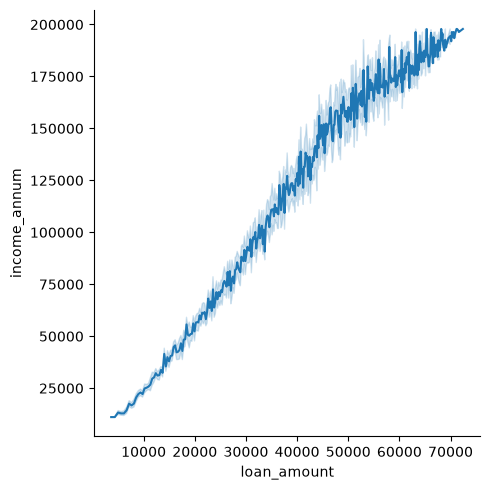

In [22]:
sns.relplot(data=df, x="loan_amount", y="income_annum", kind="line")

In [23]:
data=df
corr = data['loan_amount'].corr(data['income_annum'])
print (corr)

0.9471068988751771


In [24]:
df.shape

(4269, 13)

In [25]:
print(df.columns.tolist())

['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']


In [26]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

categorical_cols = ["education", "self_employed", "loan_status"]

for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,0,0,193404.580257,61068.480619,12,778,2400000,17600000,22700000,8000000,0
1,2,0,1,1,103202.299825,35293.577788,8,417,2700000,2200000,8800000,3300000,1
2,3,3,0,0,185916.168564,60818.308468,20,506,7100000,4500000,33300000,12800000,1
3,4,3,0,0,172158.153133,62062.737911,8,467,18200000,3300000,23300000,7900000,1
4,5,5,1,1,196371.170861,53657.953213,20,382,12400000,8200000,29400000,5000000,1


In [27]:
asset_cols = [
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value"
]
df["total_assets"] = df[asset_cols].sum(axis=1)
df.drop(columns=asset_cols, inplace=True)
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,bank_asset_value,loan_status,total_assets
0,1,2,0,0,193404.580257,61068.480619,12,778,8000000,0,42700000
1,2,0,1,1,103202.299825,35293.577788,8,417,3300000,1,13700000
2,3,3,0,0,185916.168564,60818.308468,20,506,12800000,1,44900000
3,4,3,0,0,172158.153133,62062.737911,8,467,7900000,1,44800000
4,5,5,1,1,196371.170861,53657.953213,20,382,5000000,1,50000000


In [28]:
print(len(df.columns))
print(df.columns)

11
Index(['loan_id', 'no_of_dependents', 'education', 'self_employed',
       'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
       'bank_asset_value', 'loan_status', 'total_assets'],
      dtype='str')


Gradientboosting algorithem

In [29]:
from sklearn.ensemble import GradientBoostingClassifier 
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
X = df[['education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'bank_asset_value', 'total_assets']]
y = df["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = GradientBoostingClassifier(
    n_estimators=100,   
    learning_rate=0.1,   
    max_depth=3,        
    random_state=42
)


model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.977751756440281

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.99      0.98       536
           1       0.98      0.96      0.97       318

    accuracy                           0.98       854
   macro avg       0.98      0.97      0.98       854
weighted avg       0.98      0.98      0.98       854



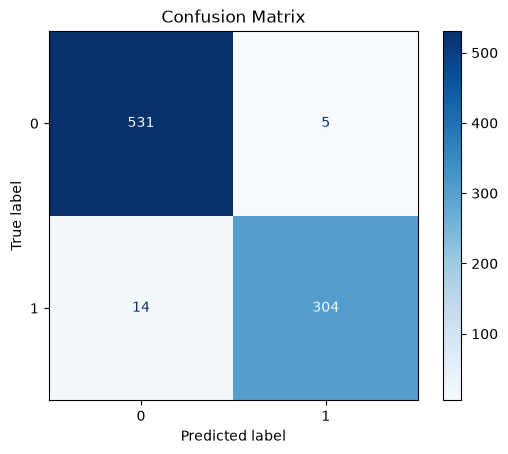

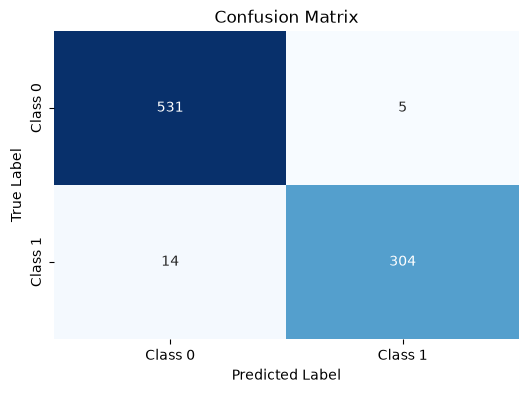

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [31]:
import pickle
pickle.dump(model, open('gradientboosting.pkl', 'wb'))
pickle.dump(df, open('dataframe.pkl', 'wb'))